# Diário da Tarefa 6 — Comparação entre os modelos

**Projeto:** Preditor de degradação de rede com RTT normalizado (independente da rota)

**Equipe:** Breno Igor Ribeiro Da Silva; Isaque Ferreira de Jesus; Lukas Paulo Alves de Carvalho; Renata Mayumi Iuvata; Ruan Abner Rodrigues Morales
**Repositório GitHub:** https://github.com/RedSwann/sistema-preditivo-de-falhas-em-redes

> A pergunta é uma só: para o alerta de rede, qual modelo é o mais adequado, e por quê? As Tarefas 3 a 5 cuidaram só da árvore. Aqui ela é comparada com Random Forest, XGBoost e dois baselines de regra.
>
> O baseline, o rótulo e os blocos continuam os da Tarefa 2. A árvore oficial continua a da Tarefa 4. Nada aqui altera o que já foi entregue.

## Contrato desta tarefa

| | Artefato | Origem / destino |
|---|---|---|
| **Entra** | `dataset_B_com_recorte_temporal.csv` e `dataset_predicao.csv` | Tarefa 2 |
| **Entra** | Parâmetros da árvore oficial | Tarefa 4 |
| **Sai** | Tabelas de comparação do detector, do preditor e de fluxos novos | Artigo |
| **Sai** | Figuras: árvore, matrizes, importâncias, profundidade e troca de rota | Artigo |
| **Sai** | Modelo mais adequado, escolhido por regra fixada antes de abrir o teste | Artigo |

## Protocolo

1. **Mesmos dados:** mesmas oito colunas relativas e mesmos blocos para todos os modelos.
2. **Ajuste honesto:** 48 combinações para cada família, com validação cruzada temporal só dentro do treino (`TimeSeriesSplit`, 3 divisões, folga de 80 linhas ≈ 5 medições de cada um dos 16 fluxos).
3. **Folga entre os blocos:** as janelas `n5_*` olham até 4 medições para trás. Por isso as 5 primeiras medições de cada fluxo na validação e no teste ficam fora da avaliação.
4. **Limiar:** escolhido na validação, sobre a probabilidade de FALHA. Só sai do padrão se melhorar a validação.
5. **Regra de decisão (fixada antes de abrir o teste):** vale a validação. Entre os modelos a até 0,002 do melhor F1 macro e do melhor recall de FALHA, fica o mais simples, nesta ordem: árvore oficial, árvore da busca, Random Forest, XGBoost. O teste só confirma.
6. **Balanceamento:** peso por classe (`sample_weight`), testado como opção nas três famílias. O peso nunca é por rota, porque isso ensinaria o mapa de novo.


In [1]:
# No Colab, rode antes: %pip install scikit-learn==1.6.1 xgboost
import io, json, platform, time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (balanced_accuracy_score, confusion_matrix, f1_score,
                             precision_recall_fscore_support)
from sklearn.model_selection import ParameterGrid, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROCESSED = Path("/content/drive/MyDrive/ripe_atlas/processed")
    FIGURAS = PROCESSED / "tarefa6" / "figuras"
    MODELOS = PROCESSED / "tarefa6"
except ImportError:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    PROCESSED = RAIZ / "data" / "processed"
    FIGURAS = RAIZ / "docs" / "img"
    MODELOS = RAIZ / "models"
SAIDA = PROCESSED / "tarefa6"
SAIDA.mkdir(exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)

CLASSES = ["OK", "RISCO", "FALHA"]
FEATURES = ["z_robusto", "aumento_pct", "jitter_relativo", "perda_pct",
            "timeout_atual", "n5_timeout", "n5_aumento80", "n5_risco"]
RANDOM_STATE = 42
FOLGA_MEDICOES = 5
PARAMS_OFICIAL = {"criterion": "gini", "max_depth": 4, "min_samples_leaf": 10, "balanceado": False}
CORES = {"OK": "#23866d", "RISCO": "#bd8420", "FALHA": "#c34e55"}
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__,
      "| pandas", pd.__version__, "| numpy", np.__version__)

det = pd.read_csv(PROCESSED / "dataset_B_com_recorte_temporal.csv", low_memory=False)
det["timestamp_utc"] = pd.to_datetime(det["timestamp_utc"], utc=True)
pred_futuro = pd.read_csv(PROCESSED / "dataset_predicao.csv", low_memory=False)
pred_futuro["timestamp_utc"] = pd.to_datetime(pred_futuro["timestamp_utc"], utc=True)
print(det["bloco_temporal"].value_counts().to_dict())
print(det["classe"].value_counts().reindex(CLASSES).to_dict())
assert len(det) == 34064 and set(FEATURES) <= set(det.columns)


Python 3.13.18 | scikit-learn 1.6.1 | xgboost 3.4.1 | pandas 2.2.3 | numpy 2.4.6


{'treino': 17028, 'teste': 10230, 'validacao': 6806}
{'OK': 26274, 'RISCO': 3848, 'FALHA': 3942}


## 1. Funções usadas em todos os modelos

Tudo fica em `Pipeline`, com a imputação ajustada só no treino. O XGBoost exige as classes como números, então o alvo é codificado da mesma forma para os três modelos. A ordem fica FALHA = 0, OK = 1, RISCO = 2.

In [2]:
cod = LabelEncoder().fit(CLASSES)
I_FALHA = int(cod.transform(["FALHA"])[0])
y_cod = lambda serie: cod.transform(serie)


def novo_modelo(familia, params):
    p = {k: v for k, v in params.items() if k != "balanceado"}
    if familia == "arvore":
        m = DecisionTreeClassifier(random_state=RANDOM_STATE, **p)
    elif familia == "floresta":
        m = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **p)
    else:
        m = XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1, eval_metric="mlogloss", **p)
    return Pipeline([("imputer", SimpleImputer(strategy="median")), ("modelo", m)])


def treinar(familia, params, X, y):
    modelo = novo_modelo(familia, params)
    pesos = compute_sample_weight("balanced", y) if params.get("balanceado") else None
    return modelo.fit(X, y, modelo__sample_weight=pesos)


def prever(modelo, X, limiar=None):
    proba = modelo.predict_proba(X)
    if limiar is None:
        return proba.argmax(axis=1)
    sem_falha = proba.copy()
    sem_falha[:, I_FALHA] = -1
    return np.where(proba[:, I_FALHA] >= limiar, I_FALHA, sem_falha.argmax(axis=1))


def nomes(y):
    return cod.inverse_transform(y)


def metricas(y, pred):
    # y e pred com os nomes das classes.
    p, r, f, s = precision_recall_fscore_support(y, pred, labels=CLASSES, zero_division=0)
    cm = confusion_matrix(y, pred, labels=CLASSES)
    return {"F1 macro": f1_score(y, pred, labels=CLASSES, average="macro", zero_division=0),
            "Recall FALHA": r[2], "Recall RISCO": r[1], "Precisão FALHA": p[2], "Precisão RISCO": p[1],
            "Balanced acc.": balanced_accuracy_score(y, pred), "Acurácia": float(np.mean(np.asarray(y) == np.asarray(pred))),
            "FALHA→RISCO": int(cm[2, 1]), "RISCO→FALHA": int(cm[1, 2]), "FALHA→OK": int(cm[2, 0]),
            "Erros": int(len(y) - np.trace(cm)), "N": int(len(y))}


def tirar_folga(tabela):
    # Tira as primeiras medições de cada fluxo no bloco (ver Protocolo, item 3).
    ordem = tabela.sort_values("timestamp_utc").groupby("fluxo_id").cumcount()
    return tabela.loc[ordem[ordem >= FOLGA_MEDICOES].index]


def blocos(tabela):
    return (tabela[tabela.bloco_temporal.eq("treino")].sort_values("timestamp_utc"),
            tabela[tabela.bloco_temporal.eq("validacao")],
            tabela[tabela.bloco_temporal.eq("teste")])


treino, validacao, teste = blocos(det)
val_f, teste_f = tirar_folga(validacao), tirar_folga(teste)
print("Treino", len(treino), "| validação sem folga", len(val_f), "de", len(validacao),
      "| teste sem folga", len(teste_f), "de", len(teste))


Treino 17028 | validação sem folga 6726 de 6806 | teste sem folga 10150 de 10230


## 2. Conferência: a árvore oficial continua a mesma?

Antes de comparar qualquer coisa, a árvore com os parâmetros da Tarefa 4 precisa repetir o teste da Tarefa 5, sem folga: 4 erros, F1 macro 0,9991 e recall de FALHA 0,9962.

In [3]:
oficial = treinar("arvore", PARAMS_OFICIAL, treino[FEATURES], y_cod(treino["classe"]))
conf = metricas(teste["classe"], nomes(prever(oficial, teste[FEATURES])))
print({k: round(conf[k], 4) for k in ["Erros", "F1 macro", "Recall FALHA", "Acurácia"]})
print(pd.DataFrame(confusion_matrix(teste["classe"], nomes(prever(oficial, teste[FEATURES])), labels=CLASSES),
                   index=[f"Real {x}" for x in CLASSES], columns=[f"Previsto {x}" for x in CLASSES]))
assert conf["Erros"] == 4 and round(conf["F1 macro"], 4) == 0.9991 and round(conf["Recall FALHA"], 4) == 0.9962
print("Bateu com a Tarefa 5.")


{'Erros': 4, 'F1 macro': 0.9991, 'Recall FALHA': np.float64(0.9962), 'Acurácia': 0.9996}
            Previsto OK  Previsto RISCO  Previsto FALHA
Real OK            8206               0               0
Real RISCO            0             968               0
Real FALHA            3               1            1052
Bateu com a Tarefa 5.


## 3. Busca de hiperparâmetros

A busca nunca toca o teste. Cada família testa 24 configurações, com e sem peso por classe. O `fit` e a nota saem só do bloco de treino, em ordem de tempo.

In [4]:
GRADES = {
    "arvore": {"criterion": ["gini", "entropy"], "max_depth": [3, 4, 6, None], "min_samples_leaf": [10, 50, 100],
               "balanceado": [False, True]},
    "floresta": {"n_estimators": [100, 200], "max_depth": [6, 12, None], "max_features": ["sqrt", None],
                 "min_samples_leaf": [1, 10], "balanceado": [False, True]},
    "xgboost": {"n_estimators": [100, 200], "max_depth": [3, 6], "learning_rate": [0.05, 0.1, 0.3],
                "reg_lambda": [1, 5], "balanceado": [False, True]},
}
print({k: len(ParameterGrid(v)) for k, v in GRADES.items()})


def buscar_cv(alvo, tr, rotulo):
    # Validação cruzada temporal dentro do treino. Devolve os melhores parâmetros de cada família.
    cv = TimeSeriesSplit(n_splits=3, gap=80)
    X, y = tr[FEATURES], y_cod(tr[alvo])
    melhores = {}
    for familia, grade in GRADES.items():
        inicio = time.perf_counter()
        linhas = []
        for params in ParameterGrid(grade):
            f1s, recs = [], []
            for i_tr, i_va in cv.split(X):
                m = treinar(familia, params, X.iloc[i_tr], y[i_tr])
                real, previsto = nomes(y[i_va]), nomes(prever(m, X.iloc[i_va]))
                r = metricas(real, previsto)
                f1s.append(r["F1 macro"]); recs.append(r["Recall FALHA"])
            linhas.append({"params": json.dumps(params), "F1 macro CV": np.mean(f1s), "Recall FALHA CV": np.mean(recs)})
        tabela = pd.DataFrame(linhas).sort_values(["F1 macro CV", "Recall FALHA CV"], ascending=False)
        tabela.to_csv(SAIDA / f"busca_{rotulo}_{familia}.csv", index=False)
        melhores[familia] = json.loads(tabela.iloc[0]["params"])
        print(f"{familia:<9} {time.perf_counter() - inicio:6.0f} s | F1 CV {tabela.iloc[0]['F1 macro CV']:.4f} | {melhores[familia]}")
    return melhores


melhores_det = buscar_cv("classe", treino, "detector")


{'arvore': 48, 'floresta': 48, 'xgboost': 48}


arvore        15 s | F1 CV 0.9994 | {'balanceado': True, 'criterion': 'entropy', 'max_depth': 6, 'min_samples_leaf': 10}


floresta      81 s | F1 CV 0.9992 | {'balanceado': True, 'max_depth': 12, 'max_features': None, 'min_samples_leaf': 1, 'n_estimators': 100}


xgboost       76 s | F1 CV 0.9982 | {'balanceado': True, 'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200, 'reg_lambda': 1}


## 4. Modelos finais, limiar e escolha na validação

Os modelos finais são treinados só no bloco de treino. O XGBoost usa parada antecipada (`early_stopping_rounds=30`) com o bloco de validação, que fica depois do treino no tempo.

O limiar é testado de 0,10 a 0,90 sobre a probabilidade de FALHA. O padrão é a classe mais provável, e um limiar só substitui o padrão se melhorar o F1 macro ou, em empate, o recall de FALHA da validação.

In [5]:
def final_xgboost(params, tr, va, alvo):
    p = {k: v for k, v in params.items() if k not in ("balanceado", "n_estimators")}
    imputer = SimpleImputer(strategy="median").fit(tr[FEATURES])
    m = XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1, eval_metric="mlogloss", n_estimators=1000,
                      early_stopping_rounds=30, **p)
    y_tr = y_cod(tr[alvo])
    pesos = compute_sample_weight("balanced", y_tr) if params.get("balanceado") else None
    m.fit(imputer.transform(tr[FEATURES]), y_tr, sample_weight=pesos,
          eval_set=[(imputer.transform(va[FEATURES]), y_cod(va[alvo]))], verbose=False)
    return Pipeline([("imputer", imputer), ("modelo", m)])


def escolher_limiar(modelo, va, alvo):
    real = va[alvo].values
    base = metricas(real, nomes(prever(modelo, va[FEATURES])))
    melhor_lim, melhor = None, (base["F1 macro"], base["Recall FALHA"])
    for lim in np.arange(0.10, 0.91, 0.05).round(2):
        r = metricas(real, nomes(prever(modelo, va[FEATURES], lim)))
        if (r["F1 macro"], r["Recall FALHA"]) > melhor:
            melhor_lim, melhor = float(lim), (r["F1 macro"], r["Recall FALHA"])
    return melhor_lim


def montar_finais(melhores, tr, va_folga, alvo, com_oficial=True):
    finais = {}
    if com_oficial:
        finais["Árvore oficial (Tarefa 4)"] = ("arvore", PARAMS_OFICIAL)
    finais["Árvore (busca)"] = ("arvore", melhores["arvore"])
    finais["Random Forest"] = ("floresta", melhores["floresta"])
    finais["XGBoost"] = ("xgboost", melhores["xgboost"])
    saida = {}
    for nome, (familia, params) in finais.items():
        inicio = time.perf_counter()
        if familia == "xgboost":
            m = final_xgboost(params, tr, va_folga, alvo)
        else:
            m = treinar(familia, params, tr[FEATURES], y_cod(tr[alvo]))
        duracao = time.perf_counter() - inicio
        saida[nome] = {"familia": familia, "params": params, "modelo": m, "treino_s": duracao,
                       "limiar": escolher_limiar(m, va_folga, alvo)}
    return saida


finais = montar_finais(melhores_det, treino, val_f, "classe")

linhas = []
for nome, info in finais.items():
    r = metricas(val_f["classe"].values, nomes(prever(info["modelo"], val_f[FEATURES], info["limiar"])))
    linhas.append({"Modelo": nome, "Limiar": info["limiar"], **r})
tab_val = pd.DataFrame(linhas).set_index("Modelo")
tab_val.round(4).to_csv(SAIDA / "comparacao_validacao_detector.csv")
display(tab_val[["Limiar", "F1 macro", "Recall FALHA", "Recall RISCO", "Balanced acc.", "Erros", "N"]].round(4))

# Regra de decisão fixada no Protocolo, antes de abrir o teste.
MARGEM = 0.002
perto = tab_val[(tab_val["F1 macro"] >= tab_val["F1 macro"].max() - MARGEM)
                & (tab_val["Recall FALHA"] >= tab_val["Recall FALHA"].max() - MARGEM)]
ordem_simplicidade = ["Árvore oficial (Tarefa 4)", "Árvore (busca)", "Random Forest", "XGBoost"]
ESCOLHIDO = next((n for n in ordem_simplicidade if n in perto.index), tab_val["F1 macro"].idxmax())
print("Candidatos dentro da margem:", list(perto.index))
print("Modelo escolhido na validação:", ESCOLHIDO)


,Limiar,F1 macro,Recall FALHA,Recall RISCO,Balanced acc.,Erros,N
Modelo,,,,,,,
Árvore oficial (Tarefa 4),None,0.9969,0.9895,0.9979,0.9958,11,6726
Árvore (busca),None,0.9985,0.9965,0.9979,0.9981,6,6726
Random Forest,None,0.9991,0.9977,0.9989,0.9988,4,6726
XGBoost,None,0.9991,0.9977,1.0000,0.9991,4,6726


Candidatos dentro da margem: ['Árvore (busca)', 'Random Forest', 'XGBoost']
Modelo escolhido na validação: Árvore (busca)


## 5. Teste temporal

Só agora o teste entra, com a folga, para todos os modelos. Nada é reajustado depois daqui. A classe majoritária é o piso: prevê sempre OK.

In [6]:
def tamanho_kb(modelo):
    buffer = io.BytesIO()
    joblib.dump(modelo, buffer)
    return buffer.tell() / 1024


def latencia_linha_ms(modelo, X):
    amostra = X.iloc[:200]
    inicio = time.perf_counter()
    for i in range(len(amostra)):
        modelo.predict(amostra.iloc[[i]])
    return (time.perf_counter() - inicio) / len(amostra) * 1000


maj = treino["classe"].mode()[0]
linhas = [{"Modelo": "Classe majoritária", "Limiar": None, **metricas(teste_f["classe"].values, np.full(len(teste_f), maj)),
           "Treino (s)": 0.0, "Predição (ms/1.000)": 0.0, "Latência 1 linha (ms)": 0.0, "Tamanho (KB)": 0.0}]
por_classe, previsoes = [], {}
for nome, info in finais.items():
    inicio = time.perf_counter()
    previsto = nomes(prever(info["modelo"], teste_f[FEATURES], info["limiar"]))
    dur = time.perf_counter() - inicio
    previsoes[nome] = previsto
    linhas.append({"Modelo": nome, "Limiar": info["limiar"], **metricas(teste_f["classe"].values, previsto),
                   "Treino (s)": info["treino_s"], "Predição (ms/1.000)": dur / len(teste_f) * 1e6,
                   "Latência 1 linha (ms)": latencia_linha_ms(info["modelo"], teste_f[FEATURES]),
                   "Tamanho (KB)": tamanho_kb(info["modelo"])})
    p, r, f, s = precision_recall_fscore_support(teste_f["classe"], previsto, labels=CLASSES, zero_division=0)
    for i, cl in enumerate(CLASSES):
        por_classe.append({"Modelo": nome, "Classe": cl, "Precisão": p[i], "Recall": r[i], "F1": f[i], "Suporte": int(s[i])})

tab_teste = pd.DataFrame(linhas).set_index("Modelo")
tab_teste.round(4).to_csv(SAIDA / "comparacao_detector.csv")
pd.DataFrame(por_classe).round(4).to_csv(SAIDA / "metricas_por_classe.csv", index=False)
display(tab_teste[["Limiar", "F1 macro", "Recall FALHA", "Recall RISCO", "Balanced acc.", "Acurácia", "Erros",
                   "FALHA→OK", "FALHA→RISCO", "RISCO→FALHA", "N"]].round(4))
display(tab_teste[["Treino (s)", "Predição (ms/1.000)", "Latência 1 linha (ms)", "Tamanho (KB)"]].round(3))
display(pd.DataFrame(por_classe).pivot(index="Modelo", columns="Classe", values=["Precisão", "Recall", "F1"]).round(4))
print("XGBoost parou com", finais["XGBoost"]["modelo"].named_steps["modelo"].best_iteration + 1, "árvores.")


,Limiar,F1 macro,Recall FALHA,Recall RISCO,Balanced acc.,Acurácia,Erros,FALHA→OK,FALHA→RISCO,RISCO→FALHA,N
Modelo,,,,,,,,,,,
Classe majoritária,None,0.2967,0.0000,0.0000,0.3333,0.8021,2009,1049,0,0,10150
Árvore oficial (Tarefa 4),None,0.9993,0.9971,1.0000,0.9990,0.9997,3,2,1,0,10150
Árvore (busca),None,0.9994,0.9981,1.0000,0.9993,0.9997,3,2,0,0,10150
Random Forest,None,0.9994,0.9981,1.0000,0.9993,0.9997,3,2,0,0,10150
XGBoost,None,0.9985,0.9971,0.9969,0.9980,0.9993,7,2,1,0,10150


,Treino (s),Predição (ms/1.000),Latência 1 linha (ms),Tamanho (KB)
Modelo,,,,
Classe majoritária,0.000,0.000,0.000,0.000
Árvore oficial (Tarefa 4),0.059,0.401,1.256,3.854
Árvore (busca),0.073,0.295,1.270,3.854
Random Forest,0.550,4.121,32.995,255.135
XGBoost,1.203,3.214,3.530,747.386


Precisão                  Recall                  \
Classe                       FALHA      OK   RISCO   FALHA      OK   RISCO   
Modelo                                                                       
Random Forest                  1.0  0.9998  0.9990  0.9981  0.9999  1.0000   
XGBoost                        1.0  0.9994  0.9979  0.9971  0.9999  0.9969   
Árvore (busca)                 1.0  0.9998  0.9990  0.9981  0.9999  1.0000   
Árvore oficial (Tarefa 4)      1.0  0.9998  0.9990  0.9971  1.0000  1.0000   

                               F1                  
Classe                      FALHA      OK   RISCO  
Modelo                                             
Random Forest              0.9990  0.9998  0.9995  
XGBoost                    0.9986  0.9996  0.9974  
Árvore (busca)             0.9990  0.9998  0.9995  
Árvore oficial (Tarefa 4)  0.9986  0.9999  0.9995

XGBoost parou com 215 árvores.


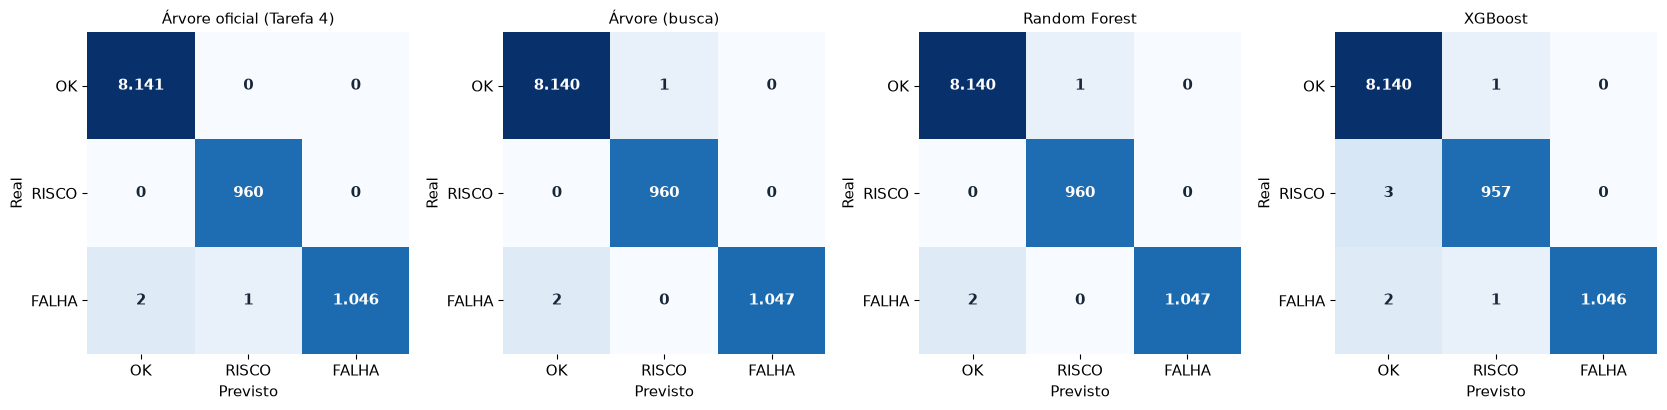

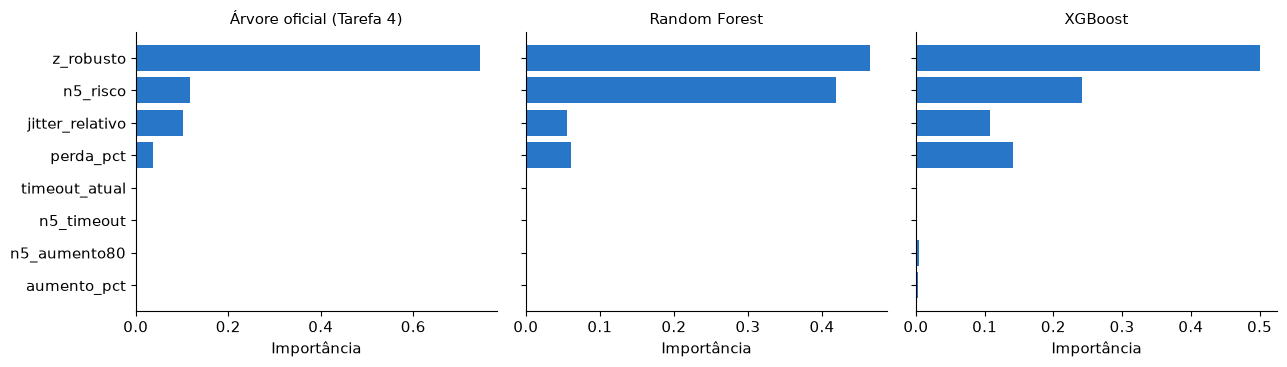

In [7]:
# Matrizes de confusão em contagem, uma para cada modelo.
fig, eixos = plt.subplots(1, len(finais), figsize=(4.2 * len(finais), 4))
for eixo, (nome, previsto) in zip(eixos, previsoes.items()):
    cm = confusion_matrix(teste_f["classe"], previsto, labels=CLASSES)
    eixo.imshow(np.log1p(cm), cmap="Blues")
    eixo.set_title(nome, fontsize=11)
    eixo.set_xticks(range(3), CLASSES); eixo.set_yticks(range(3), CLASSES)
    eixo.set_xlabel("Previsto"); eixo.set_ylabel("Real")
    eixo.spines[:].set_visible(False)
    for i in range(3):
        for j in range(3):
            eixo.text(j, i, f"{cm[i, j]:,}".replace(",", "."), ha="center", va="center",
                      color="white" if cm[i, j] > 300 else "#182638", fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURAS / "matrizes_confusao.png", dpi=150, bbox_inches="tight")
plt.show()

# Importância dos atributos: o que mais pesa no alerta.
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
ordem = None
for eixo, nome in zip(eixos, ["Árvore oficial (Tarefa 4)", "Random Forest", "XGBoost"]):
    imp = pd.Series(finais[nome]["modelo"].named_steps["modelo"].feature_importances_, index=FEATURES)
    ordem = imp.sort_values().index if ordem is None else ordem
    eixo.barh(ordem, imp[ordem], color="#2876c7")
    eixo.set_title(nome, fontsize=11)
    eixo.set_xlabel("Importância")
fig.tight_layout()
fig.savefig(FIGURAS / "importancia_atributos.png", dpi=150, bbox_inches="tight")
plt.show()
pd.DataFrame({n: finais[n]["modelo"].named_steps["modelo"].feature_importances_ for n in
              ["Árvore oficial (Tarefa 4)", "Random Forest", "XGBoost"]}, index=FEATURES).round(4).to_csv(SAIDA / "importancia_atributos.csv")


### A figura da árvore

As figuras gravadas nas Tarefas 3 e 4 passavam `class_names=CLASSES`, na ordem OK, RISCO, FALHA. O scikit-learn guarda as classes em ordem alfabética (FALHA, OK, RISCO), então o desenho saía com os nomes trocados, embora as regras em texto estivessem certas. As células daquelas tarefas foram corrigidas. Aqui os nomes vêm do próprio modelo.

Para a figura, a árvore é treinada com os nomes das classes, de modo que `classes_` sai igual ao modelo entregue.

Ordem das classes no modelo: ['FALHA', 'OK', 'RISCO']


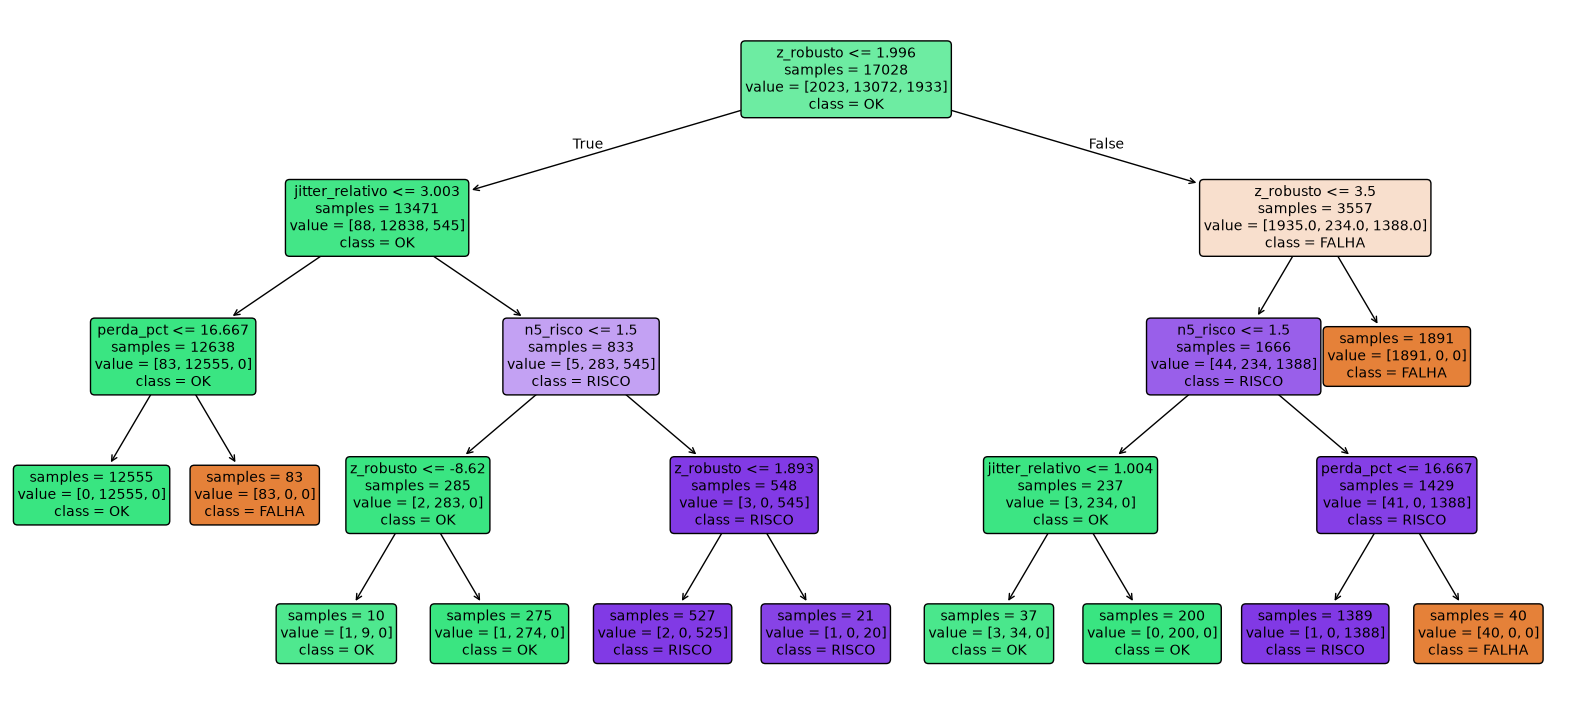

,profundidade,F1 treino,F1 validação,folhas
0,1,0.5536,0.5561,2
1,2,0.9384,0.9539,4
2,3,0.9921,0.9951,7
3,4,0.9998,0.9987,11
4,5,1.0000,0.9991,12
5,6,1.0000,0.9991,12
6,8,1.0000,0.9991,12
7,10,1.0000,0.9991,12
8,15,1.0000,0.9991,12
9,sem limite,1.0000,0.9991,12


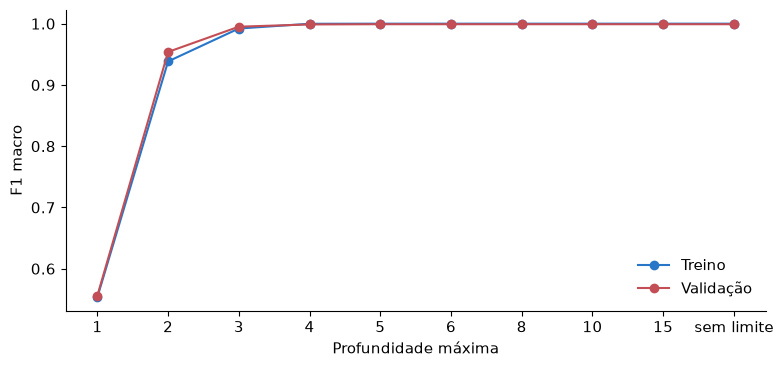

Acurácia out-of-bag da floresta: 0.9998


In [8]:
arvore_nomes = treinar("arvore", PARAMS_OFICIAL, treino[FEATURES], treino["classe"]).named_steps["modelo"]
print("Ordem das classes no modelo:", list(arvore_nomes.classes_))
plt.figure(figsize=(20, 9))
plot_tree(arvore_nomes, feature_names=FEATURES, class_names=list(arvore_nomes.classes_), filled=True, rounded=True,
          impurity=False, fontsize=10)
plt.savefig(FIGURAS / "arvore_oficial.png", dpi=130, bbox_inches="tight")
plt.show()

# Profundidade x overfitting: treino e validação, sem mexer no teste.
curva = []
for prof in [1, 2, 3, 4, 5, 6, 8, 10, 15, None]:
    m = treinar("arvore", {"criterion": "gini", "max_depth": prof, "min_samples_leaf": 1}, treino[FEATURES], y_cod(treino["classe"]))
    curva.append({"profundidade": "sem limite" if prof is None else prof,
                  "F1 treino": metricas(treino["classe"].values, nomes(prever(m, treino[FEATURES])))["F1 macro"],
                  "F1 validação": metricas(val_f["classe"].values, nomes(prever(m, val_f[FEATURES])))["F1 macro"],
                  "folhas": m.named_steps["modelo"].get_n_leaves()})
curva = pd.DataFrame(curva)
curva.round(4).to_csv(SAIDA / "curva_profundidade.csv", index=False)
display(curva.round(4))
plt.figure(figsize=(8, 3.8))
x = range(len(curva))
plt.plot(x, curva["F1 treino"], marker="o", color="#2876c7", label="Treino")
plt.plot(x, curva["F1 validação"], marker="o", color="#c34e55", label="Validação")
plt.xticks(x, curva["profundidade"]); plt.xlabel("Profundidade máxima"); plt.ylabel("F1 macro"); plt.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIGURAS / "curva_profundidade.png", dpi=150); plt.show()

# Erro out-of-bag da floresta, para fechar os conceitos do artigo.
oob_params = {k: v for k, v in melhores_det["floresta"].items() if k != "balanceado"}
imputado = SimpleImputer(strategy="median").fit_transform(treino[FEATURES])
oob = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, oob_score=True, **oob_params).fit(imputado, y_cod(treino["classe"]))
print("Acurácia out-of-bag da floresta:", round(oob.oob_score_, 4))


## 6. O alvo futuro: 12 minutos à frente

O preditor só tem utilidade se superar a persistência, a regra que repete o estado atual. As colunas de entrada continuam as oito de sempre, em `t`. O alvo é `status_futuro`, a classe do mesmo fluxo perto de `t + 12 min` (±60 s), ou seja, cerca de 3 medições depois. Pares cujo alvo cairia em outro bloco já foram descartados na Tarefa 2.

In [9]:
tr_p, va_p, te_p = blocos(pred_futuro)
va_pf, te_pf = tirar_folga(va_p), tirar_folga(te_p)
print("Treino", len(tr_p), "| validação", len(va_pf), "| teste", len(te_pf))

melhores_pred = buscar_cv("status_futuro", tr_p, "preditor")
finais_pred = montar_finais(melhores_pred, tr_p, va_pf, "status_futuro", com_oficial=False)

maj_p = tr_p["status_futuro"].mode()[0]
real = te_pf["status_futuro"].values
linhas = [{"Modelo": "Classe majoritária", "Limiar": None, **metricas(real, np.full(len(real), maj_p))},
          {"Modelo": "Persistência", "Limiar": None, **metricas(real, te_pf["previsao_persistencia"].values)}]
for nome, info in finais_pred.items():
    linhas.append({"Modelo": nome, "Limiar": info["limiar"], **metricas(real, nomes(prever(info["modelo"], te_pf[FEATURES], info["limiar"])))})
tab_pred = pd.DataFrame(linhas).set_index("Modelo")
tab_pred.round(4).to_csv(SAIDA / "comparacao_preditor.csv")
display(tab_pred[["Limiar", "F1 macro", "Recall FALHA", "Recall RISCO", "Balanced acc.", "Acurácia", "Erros", "N"]].round(4))

pers = tab_pred.loc["Persistência"]
modelos_p = tab_pred.drop(["Classe majoritária", "Persistência"])
supera = modelos_p[(modelos_p["F1 macro"] > pers["F1 macro"]) & (modelos_p["Recall FALHA"] > pers["Recall FALHA"])]
print("Modelos que superam a persistência em F1 macro E em recall de FALHA:", list(supera.index))


Treino 16805 | validação 6632 | teste 10001


arvore         9 s | F1 CV 0.7957 | {'balanceado': False, 'criterion': 'gini', 'max_depth': 6, 'min_samples_leaf': 50}


floresta     106 s | F1 CV 0.7812 | {'balanceado': True, 'max_depth': 12, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'n_estimators': 200}


xgboost       93 s | F1 CV 0.7756 | {'balanceado': True, 'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'reg_lambda': 5}


,Limiar,F1 macro,Recall FALHA,Recall RISCO,Balanced acc.,Acurácia,Erros,N
Modelo,,,,,,,,
Classe majoritária,NaN,0.2966,0.0000,0.0000,0.3333,0.8014,1986,10001
Persistência,NaN,0.8106,0.7471,0.7379,0.8110,0.9072,928,10001
Árvore (busca),NaN,0.8425,0.7056,0.6926,0.7949,0.9294,706,10001
Random Forest,0.6,0.8175,0.6959,0.7916,0.8137,0.9114,886,10001
XGBoost,0.6,0.8051,0.6902,0.8053,0.8123,0.9025,975,10001


Modelos que superam a persistência em F1 macro E em recall de FALHA: []


## 7. Segundo protocolo: fluxos nunca vistos

Num modelo que serve para outra rede, um fluxo inteiro precisa poder ficar fora do treino. Os 16 fluxos são ordenados pela mediana do baseline e divididos em 4 grupos, cada grupo indo de caminhos curtos a longos. Em cada rodada:

- 12 fluxos treinam (bloco de treino) e escolhem hiperparâmetros (bloco de validação, com folga);
- 4 fluxos ficam inteiramente fora e só aparecem no bloco de teste, com folga;
- o baseline deles vem só do Período A deles, como em todos os outros.

Assim, ao contrário do teste auxiliar da Tarefa 5, os fluxos reservados também não influenciam os hiperparâmetros. A árvore oficial entra com os parâmetros congelados. Isso é uma pequena contaminação (eles foram escolhidos com todos os fluxos), declarada aqui.

In [10]:
def buscar_holdout(tr, va_folga):
    melhores = {}
    for familia, grade in GRADES.items():
        melhor, melhor_nota = None, (-1, -1)
        for params in ParameterGrid(grade):
            m = treinar(familia, params, tr[FEATURES], y_cod(tr["classe"]))
            r = metricas(va_folga["classe"].values, nomes(prever(m, va_folga[FEATURES])))
            if (r["F1 macro"], r["Recall FALHA"]) > melhor_nota:
                melhor, melhor_nota = params, (r["F1 macro"], r["Recall FALHA"])
        melhores[familia] = melhor
    return melhores


medianas = det.groupby("fluxo_id")["mediana"].first().sort_values()
q1, q3 = medianas.quantile([0.25, 0.75])
tipo = medianas.map(lambda v: "curto" if v <= q1 else ("longo" if v >= q3 else "intermediário"))
grupos = [list(medianas.index[i::4]) for i in range(4)]
acumulado = {}
inicio = time.perf_counter()
for i, reservados in enumerate(grupos, 1):
    tr_n = treino[~treino.fluxo_id.isin(reservados)]
    va_n = val_f[~val_f.fluxo_id.isin(reservados)]
    te_n = teste_f[teste_f.fluxo_id.isin(reservados)]
    melhores_n = buscar_holdout(tr_n, va_n)
    modelos_n = {"Árvore oficial (Tarefa 4)": treinar("arvore", PARAMS_OFICIAL, tr_n[FEATURES], y_cod(tr_n["classe"])),
                 "Árvore (busca)": treinar("arvore", melhores_n["arvore"], tr_n[FEATURES], y_cod(tr_n["classe"])),
                 "Random Forest": treinar("floresta", melhores_n["floresta"], tr_n[FEATURES], y_cod(tr_n["classe"])),
                 "XGBoost": treinar("xgboost", melhores_n["xgboost"], tr_n[FEATURES], y_cod(tr_n["classe"]))}
    for nome, m in modelos_n.items():
        acumulado.setdefault(nome, []).append(pd.DataFrame({
            "fluxo_id": te_n["fluxo_id"].values, "real": te_n["classe"].values,
            "previsto": nomes(prever(m, te_n[FEATURES]))}))
    print(f"Rodada {i}: reservados {reservados} | {time.perf_counter() - inicio:.0f} s")

linhas = []
for nome, partes in acumulado.items():
    tudo = pd.concat(partes)
    linhas.append({"Modelo": nome, "Fluxos": "todos", **metricas(tudo["real"].values, tudo["previsto"].values)})
    for t in ["curto", "longo"]:
        x = tudo[tudo.fluxo_id.map(tipo).eq(t)]
        linhas.append({"Modelo": nome, "Fluxos": t, **metricas(x["real"].values, x["previsto"].values)})
tab_novos = pd.DataFrame(linhas).set_index(["Modelo", "Fluxos"])
tab_novos.round(4).to_csv(SAIDA / "comparacao_fluxos_novos.csv")
display(tab_novos[["F1 macro", "Recall FALHA", "Recall RISCO", "Balanced acc.", "Erros", "N"]].round(4))


Rodada 1: reservados ['6977|45.11.105.136', '7751|23.26.247.12', '6884|54.39.185.31', '6811|54.39.185.31'] | 69 s


Rodada 2: reservados ['7113|45.11.105.136', '7150|23.26.247.12', '7202|103.96.67.60', '7108|103.52.117.1'] | 137 s


Rodada 3: reservados ['6410|45.11.105.136', '7378|23.26.247.12', '7796|103.96.67.60', '6521|103.52.117.1'] | 220 s


Rodada 4: reservados ['7708|45.11.105.136', '7346|54.39.185.31', '6681|103.52.117.1', '7423|103.52.117.1'] | 302 s


F1 macro  Recall FALHA  Recall RISCO  \
Modelo                    Fluxos                                         
Árvore oficial (Tarefa 4) todos     0.9969        0.9924        0.9990   
                          curto     0.9984        1.0000        1.0000   
                          longo     0.9848        0.9890        1.0000   
Árvore (busca)            todos     0.9981        0.9924        1.0000   
                          curto     1.0000        1.0000        1.0000   
                          longo     0.9922        0.9890        1.0000   
Random Forest             todos     0.9993        0.9971        1.0000   
                          curto     0.9971        0.9919        1.0000   
                          longo     0.9993        0.9972        1.0000   
XGBoost                   todos     0.9983        0.9943        0.9990   
                          curto     0.9912        0.9756        0.9909   
                          longo     0.9993        0.9972        1.0000   

                                  Balanced acc.  Erros      N  
Modelo                    Fluxos                               
Árvore oficial (Tarefa 4) todos          0.9969     14  10150  
                          curto          0.9999      1   2554  
                          longo          0.9956     12   2552  
Árvore (busca)            todos          0.9975      8  10150  
                          curto          1.0000      0   2554  
                          longo          0.9963      8   2552  
Random Forest             todos          0.9990      3  10150  
                          curto          0.9973      1   2554  
                          longo          0.9991      2   2552  
XGBoost                   todos          0.9977      7  10150  
                          curto          0.9888      4   2554  
                          longo          0.9991      2   2552

## 8. Mudança de rota: o que os rótulos estão chamando de falha?

O rótulo olha cada medição contra uma ficha congelada. Quando o caminho troca de patamar e fica estável, o RTT passa a ser "alto" contra a ficha antiga, mesmo com perda e jitter normais. Isso é novo encaminhamento, não pane.

Os rótulos oficiais continuam como foram entregues. Esta seção mede o tamanho do problema com uma regra simples e conservadora, olhando as últimas 90 medições do fluxo (cerca de 6 horas):

| Critério | Limite |
|---|---|
| Patamar deslocado | `\|mediana de z_robusto\|` ≥ 2 |
| Patamar estável | IQR do RTT ≤ 1% da mediana da janela |
| Perda próxima do normal | média de `perda_pct` ≤ 2% |
| Jitter baixo | mediana de `jitter_relativo` ≤ 1,5 |

A regra usa só o passado do fluxo. Ela marca a linha, não muda a classe. Depois, os modelos são treinados sem as linhas marcadas e avaliados no teste com e sem elas.

,medicoes,marcadas,pct_FALHA,pct_RISCO,pct_marcadas,mediana_A,mediana_B
fluxo_id,,,,,,,
6681|103.52.117.1,2160,1375,2.92,91.39,63.66,292.27,335.20
6521|103.52.117.1,2130,1071,2.35,16.20,50.28,363.03,356.00
7108|103.52.117.1,2143,990,79.75,1.87,46.20,338.50,344.41
7202|103.96.67.60,2136,903,22.85,13.20,42.28,244.19,234.20
7150|23.26.247.12,2152,462,0.23,0.28,21.47,54.42,54.23
7378|23.26.247.12,2159,463,3.52,0.42,21.45,54.44,54.39
6811|54.39.185.31,2151,82,11.39,1.12,3.81,294.91,294.85
7751|23.26.247.12,2048,65,2.34,2.78,3.17,54.18,53.87
7113|45.11.105.136,2143,0,3.22,1.96,0.00,0.93,0.93


classe,OK,RISCO,FALHA
janela_mudanca_rota,,,
False,23418,2288,2947
True,2856,1560,995


Linhas marcadas: 5411 de 34064 (15.9%)
Das FALHA, 25.2% estão em janela marcada; das RISCO, 40.5%.


Treino sem marcadas: 15063 de 17028


F1 macro  Recall FALHA  \
Modelo                    Teste                                         
Árvore oficial (Tarefa 4) completo               0.9993        0.9971   
                          sem linhas marcadas    0.9987        0.9953   
Random Forest             completo               0.9994        0.9981   
                          sem linhas marcadas    0.9989        0.9968   
XGBoost                   completo               0.9989        0.9981   
                          sem linhas marcadas    0.9973        0.9968   

                                               Recall RISCO  Erros      N  
Modelo                    Teste                                            
Árvore oficial (Tarefa 4) completo                   1.0000      3  10150  
                          sem linhas marcadas        1.0000      3   7493  
Random Forest             completo                   1.0000      3  10150  
                          sem linhas marcadas        1.0000      3   7493  
XGBoost                   completo                   0.9958      6  10150  
                          sem linhas marcadas        0.9881      6   7493

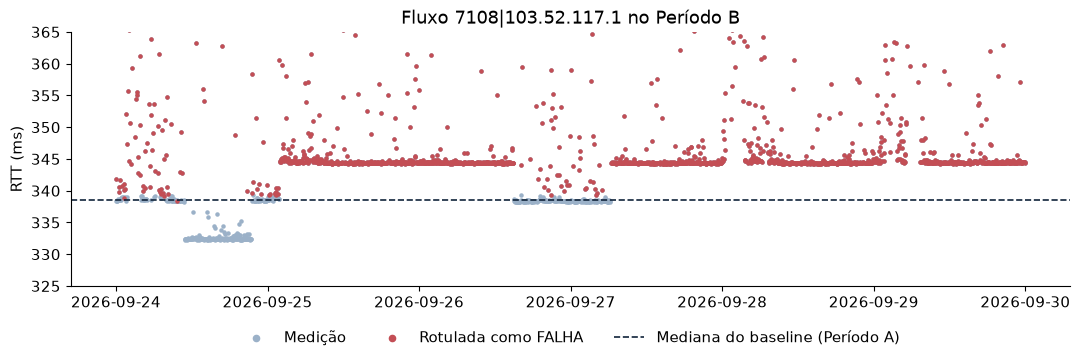

In [11]:
JANELA = 90
ordenado = det.sort_values(["fluxo_id", "timestamp_utc"]).copy()
g = ordenado.groupby("fluxo_id")
rolar = lambda coluna, funcao: g[coluna].transform(lambda s: getattr(s.rolling(JANELA, min_periods=JANELA), funcao)())
z_janela = rolar("z_robusto", "median")
rtt_janela = rolar("rtt_ms", "median")
q1_j = g["rtt_ms"].transform(lambda s: s.rolling(JANELA, min_periods=JANELA).quantile(0.25))
q3_j = g["rtt_ms"].transform(lambda s: s.rolling(JANELA, min_periods=JANELA).quantile(0.75))
ordenado["janela_mudanca_rota"] = (z_janela.abs().ge(2) & ((q3_j - q1_j) / rtt_janela * 100).le(1)
                                   & rolar("perda_pct", "mean").le(2) & rolar("jitter_relativo", "median").le(1.5))

resumo_rota = ordenado.groupby("fluxo_id").agg(medicoes=("classe", "size"), marcadas=("janela_mudanca_rota", "sum"),
                                               pct_FALHA=("classe", lambda s: (s == "FALHA").mean() * 100),
                                               pct_RISCO=("classe", lambda s: (s == "RISCO").mean() * 100))
resumo_rota["pct_marcadas"] = resumo_rota["marcadas"] / resumo_rota["medicoes"] * 100
resumo_rota["mediana_A"] = ordenado.groupby("fluxo_id")["mediana"].first()
resumo_rota["mediana_B"] = ordenado.groupby("fluxo_id")["rtt_ms"].median()
resumo_rota.round(2).to_csv(SAIDA / "mudanca_rota_por_fluxo.csv")
display(resumo_rota.sort_values("pct_marcadas", ascending=False).round(2))
cruz = pd.crosstab(ordenado["janela_mudanca_rota"], ordenado["classe"])[CLASSES]
cruz.to_csv(SAIDA / "mudanca_rota_por_classe.csv")
display(cruz)
print(f"Linhas marcadas: {ordenado.janela_mudanca_rota.sum()} de {len(ordenado)} ({ordenado.janela_mudanca_rota.mean():.1%})")
print(f"Das FALHA, {cruz.loc[True, 'FALHA'] / cruz['FALHA'].sum():.1%} estão em janela marcada; das RISCO, {cruz.loc[True, 'RISCO'] / cruz['RISCO'].sum():.1%}.")

marcadas = ordenado.loc[ordenado.janela_mudanca_rota, ["fluxo_id", "timestamp_utc"]].assign(marcada=True)
marcar = lambda t: t.merge(marcadas, on=["fluxo_id", "timestamp_utc"], how="left")["marcada"].notna().values
tr_limpo = treino[~marcar(treino)]
linhas = []
te_marc = marcar(teste_f)
for nome, (familia, params) in {"Árvore oficial (Tarefa 4)": ("arvore", PARAMS_OFICIAL),
                                "Random Forest": ("floresta", melhores_det["floresta"]),
                                "XGBoost": ("xgboost", melhores_det["xgboost"])}.items():
    m = treinar(familia, params, tr_limpo[FEATURES], y_cod(tr_limpo["classe"]))
    p = nomes(prever(m, teste_f[FEATURES]))
    linhas.append({"Modelo": nome, "Teste": "completo", **metricas(teste_f["classe"].values, p)})
    linhas.append({"Modelo": nome, "Teste": "sem linhas marcadas", **metricas(teste_f["classe"].values[~te_marc], p[~te_marc])})
tab_rota = pd.DataFrame(linhas).set_index(["Modelo", "Teste"])
tab_rota.round(4).to_csv(SAIDA / "sensibilidade_mudanca_rota.csv")
print("Treino sem marcadas:", len(tr_limpo), "de", len(treino))
display(tab_rota[["F1 macro", "Recall FALHA", "Recall RISCO", "Erros", "N"]].round(4))

fig, eixo = plt.subplots(figsize=(11, 3.8))
x = ordenado[ordenado.fluxo_id.eq("7108|103.52.117.1")]
eixo.scatter(x["timestamp_utc"], x["rtt_ms"], s=5, color="#9bb1c8", label="Medição")
eixo.scatter(x.loc[x.classe.eq("FALHA"), "timestamp_utc"], x.loc[x.classe.eq("FALHA"), "rtt_ms"], s=5, color=CORES["FALHA"], label="Rotulada como FALHA")
eixo.axhline(x["mediana"].iloc[0], color="#10243b", ls="--", lw=1.2, label="Mediana do baseline (Período A)")
eixo.set_ylim(325, 365); eixo.set_ylabel("RTT (ms)"); eixo.set_title("Fluxo 7108|103.52.117.1 no Período B")
eixo.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12), markerscale=2)
fig.tight_layout(); fig.savefig(FIGURAS / "mudanca_rota_7108.png", dpi=150, bbox_inches="tight"); plt.show()


## 9. Figuras de apoio para o artigo

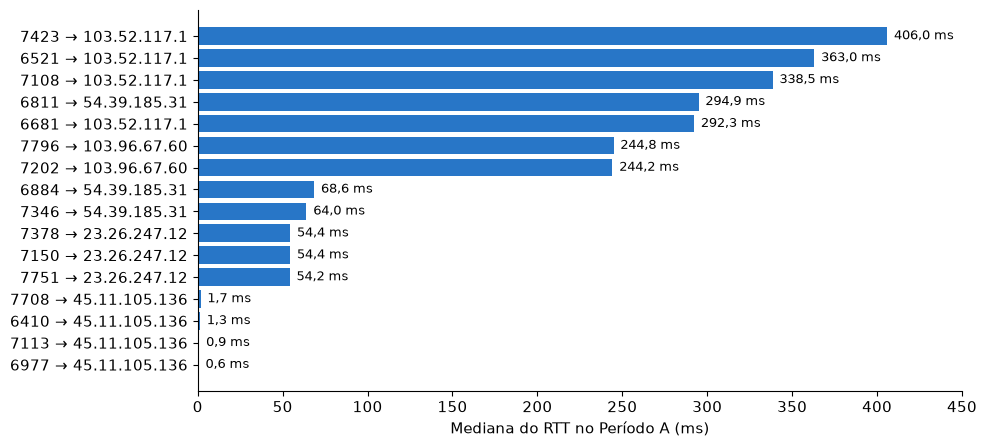

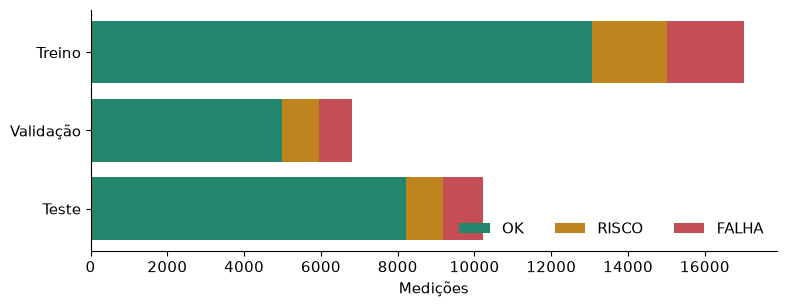

classe,OK,RISCO,FALHA
bloco_temporal,,,
treino,13072,1933,2023
validacao,4996,947,863
teste,8206,968,1056


classe,OK,RISCO,FALHA
fluxo_id,,,
6410|45.11.105.136,73.4,11.3,15.4
6521|103.52.117.1,81.5,16.2,2.3
6681|103.52.117.1,5.7,91.4,2.9
6811|54.39.185.31,87.5,1.1,11.4
6884|54.39.185.31,92.5,2.3,5.2
6977|45.11.105.136,95.4,2.6,2.1
7108|103.52.117.1,18.4,1.9,79.7
7113|45.11.105.136,94.8,2.0,3.2
7150|23.26.247.12,99.5,0.3,0.2


In [12]:
# Distância não é defeito: um caminho curto e um longo, cada um com seu normal.
base = pd.read_csv(PROCESSED / "baseline_por_fluxo.csv")
ok = base[base.status_baseline.eq("baseline_ok")].sort_values("mediana")
fig, eixo = plt.subplots(figsize=(10, 4.6))
rotulos_f = [f.replace("|", " → ") for f in ok["fluxo_id"]]
eixo.barh(rotulos_f, ok["mediana"], color="#2876c7")
for i, v in enumerate(ok["mediana"]):
    eixo.text(v + 4, i, f"{v:.1f} ms".replace(".", ","), va="center", fontsize=9)
eixo.set_xlabel("Mediana do RTT no Período A (ms)"); eixo.set_xlim(0, 450)
fig.tight_layout(); fig.savefig(FIGURAS / "baseline_por_fluxo.png", dpi=150); plt.show()

# Distribuição das classes por bloco.
dist = pd.crosstab(det["bloco_temporal"], det["classe"]).reindex(index=["treino", "validacao", "teste"], columns=CLASSES)
dist.to_csv(SAIDA / "distribuicao_classes.csv")
fig, eixo = plt.subplots(figsize=(8, 3.2))
esquerda = np.zeros(3)
nomes_blocos = ["Treino", "Validação", "Teste"]
for cl in CLASSES:
    eixo.barh(nomes_blocos, dist[cl], left=esquerda, color=CORES[cl], label=cl)
    esquerda += dist[cl].values
eixo.invert_yaxis(); eixo.set_xlabel("Medições"); eixo.legend(frameon=False, ncol=3, loc="lower right")
fig.tight_layout(); fig.savefig(FIGURAS / "distribuicao_classes.png", dpi=150); plt.show()
display(dist)
display((pd.crosstab(det["fluxo_id"], det["classe"], normalize="index") * 100)[CLASSES].round(1))


Profundidade: 6 | folhas: 11


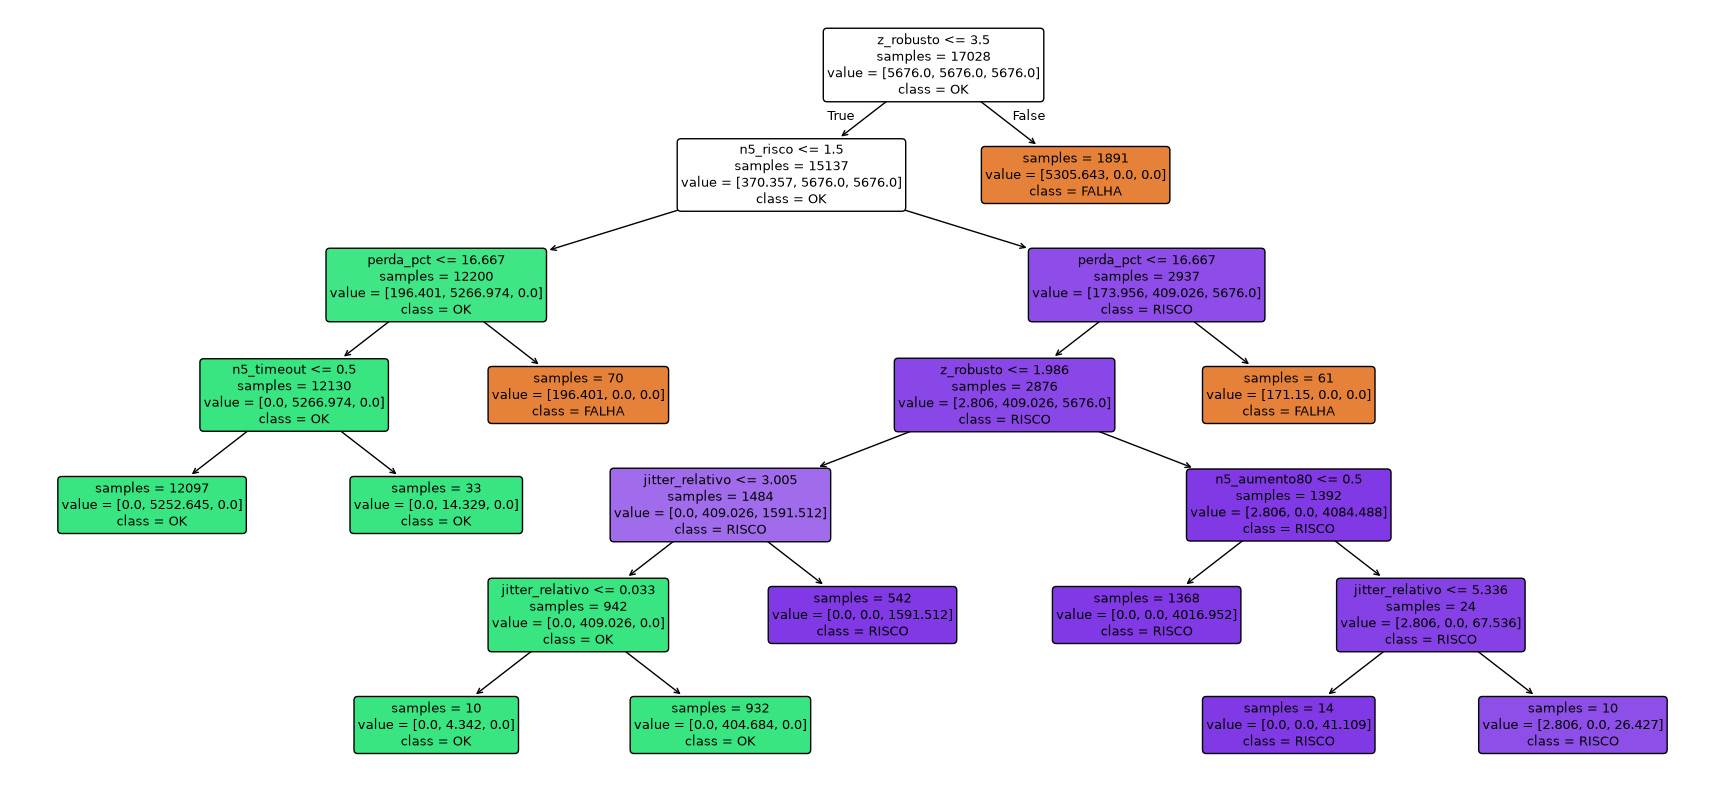

|--- z_robusto <= 3.50
|   |--- n5_risco <= 1.50
|   |   |--- perda_pct <= 16.67
|   |   |   |--- n5_timeout <= 0.50
|   |   |   |   |--- class: OK
|   |   |   |--- n5_timeout >  0.50
|   |   |   |   |--- class: OK
|   |   |--- perda_pct >  16.67
|   |   |   |--- class: FALHA
|   |--- n5_risco >  1.50
|   |   |--- perda_pct <= 16.67
|   |   |   |--- z_robusto <= 1.99
|   |   |   |   |--- jitter_relativo <= 3.00
|   |   |   |   |   |--- jitter_relativo <= 0.03
|   |   |   |   |   |   |--- class: OK
|   |   |   |   |   |--- jitter_relativo >  0.03
|   |   |   |   |   |   |--- class: OK
|   |   |   |   |--- jitter_relativo >  3.00
|   |   |   |   |   |--- class: RISCO
|   |   |   |--- z_robusto >  1.99
|   |   |   |   |--- n5_aumento80 <= 0.50
|   |   |   |   |   |--- class: RISCO
|   |   |   |   |--- n5_aumento80 >  0.50
|   |   |   |   |   |--- jitter_relativo <= 5.34
|   |   |   |   |   |   |--- class: RISCO
|   |   |   |   |   |--- jitter_relativo >  5.34
|   |   |   |   |   |   |--- 

In [13]:
# Figura da árvore escolhida, com os nomes das classes vindos do próprio modelo.
info = finais[ESCOLHIDO]
if info["familia"] == "arvore":
    arvore_final = treinar("arvore", info["params"], treino[FEATURES], treino["classe"]).named_steps["modelo"]
    print("Profundidade:", arvore_final.get_depth(), "| folhas:", arvore_final.get_n_leaves())
    plt.figure(figsize=(22, 10))
    plot_tree(arvore_final, feature_names=FEATURES, class_names=list(arvore_final.classes_), filled=True, rounded=True,
              impurity=False, fontsize=9)
    plt.savefig(FIGURAS / "arvore_escolhida.png", dpi=130, bbox_inches="tight")
    plt.show()
    from sklearn.tree import export_text
    regras = export_text(arvore_final, feature_names=FEATURES, class_names=list(arvore_final.classes_))
    (SAIDA / "regras_arvore_escolhida.txt").write_text(regras, encoding="utf-8")
    print(regras)

# O modelo entregue em models/modelo.joblib continua sendo a árvore oficial da Tarefa 5.
_ = joblib.dump({"modelo": info["modelo"], "features": FEATURES, "classes_codificadas": list(cod.classes_),
             "limiar": info["limiar"], "params": info["params"], "nome": ESCOLHIDO},
            MODELOS / "modelo_tarefa6.joblib")


In [14]:
# Registro final: modelo escolhido, parâmetros e ambiente.
resumo = {
    "modelo_escolhido": ESCOLHIDO,
    "parametros": {n: i["params"] for n, i in finais.items()},
    "limiares": {n: i["limiar"] for n, i in finais.items()},
    "parametros_preditor": {n: i["params"] for n, i in finais_pred.items()},
    "xgboost_arvores_early_stopping": int(finais["XGBoost"]["modelo"].named_steps["modelo"].best_iteration + 1),
    "oob_floresta": float(oob.oob_score_),
    "ambiente": {"python": platform.python_version(), "scikit_learn": sklearn.__version__, "xgboost": xgboost.__version__,
                 "pandas": pd.__version__, "numpy": np.__version__, "joblib": joblib.__version__},
}
with open(SAIDA / "resumo_tarefa6.json", "w", encoding="utf-8") as f:
    json.dump(resumo, f, ensure_ascii=False, indent=2)
print(json.dumps(resumo, ensure_ascii=False, indent=2))


{
  "modelo_escolhido": "Árvore (busca)",
  "parametros": {
    "Árvore oficial (Tarefa 4)": {
      "criterion": "gini",
      "max_depth": 4,
      "min_samples_leaf": 10,
      "balanceado": false
    },
    "Árvore (busca)": {
      "balanceado": true,
      "criterion": "entropy",
      "max_depth": 6,
      "min_samples_leaf": 10
    },
    "Random Forest": {
      "balanceado": true,
      "max_depth": 12,
      "max_features": null,
      "min_samples_leaf": 1,
      "n_estimators": 100
    },
    "XGBoost": {
      "balanceado": true,
      "learning_rate": 0.05,
      "max_depth": 3,
      "n_estimators": 200,
      "reg_lambda": 1
    }
  },
  "limiares": {
    "Árvore oficial (Tarefa 4)": null,
    "Árvore (busca)": null,
    "Random Forest": null,
    "XGBoost": null
  },
  "parametros_preditor": {
    "Árvore (busca)": {
      "balanceado": false,
      "criterion": "gini",
      "max_depth": 6,
      "min_samples_leaf": 50
    },
    "Random Forest": {
      "balanceado"

## 10. O que os resultados dizem

**Detector.** Pela regra fixada no Protocolo, a escolha é a **árvore da busca** (entropia, profundidade máxima 6, folha mínima 10, com peso por classe). Na validação, a árvore oficial ficou fora da margem (recall de FALHA 0,9895, contra o mínimo de 0,9957). A árvore da busca, a Random Forest e o XGBoost ficaram dentro, e a árvore é a mais simples dos três.

O teste confirmou: a árvore da busca e a Random Forest erraram 3 de 10.150 medições, a árvore oficial também errou 3, e o XGBoost errou 7. A diferença entre eles é de poucas linhas, então não sustenta dizer que um modelo é muito mais preciso que o outro. O que desempata é o custo: a árvore é a mais rápida para decidir e a menor em disco, e um operador consegue ler o caminho da raiz até a folha.

**Modelo entregue.** A entrega de 04/11/2026 (versão 1.0.0) traz a árvore oficial da Tarefa 5, e ela não foi trocada. Esta comparação veio depois. No mesmo teste com folga, as duas árvores erram 3 medições e diferem em 1 FALHA detectada (1.046 e 1.047 de 1.049), então o ganho é pequeno.

**Baseline.** A classe majoritária acerta 80,21% das medições e tem recall zero de FALHA. Isso mostra por que a acurácia sozinha engana. Todos os modelos superam esse piso com folga.

**Preditor.** Nenhum modelo superou a persistência nas duas métricas. A árvore ganhou em F1 macro (0,8425 contra 0,8106), mas perdeu em recall de FALHA (0,7056 contra 0,7471), que é o erro mais caro. Por isso o entregável continua sendo um **detector do estado atual**.

**Fluxos novos.** A Random Forest foi um pouco melhor (3 erros, contra 8 da árvore da busca e 14 da árvore oficial, em 10.150). Se a prioridade fosse só operar em caminhos nunca vistos, ela seria uma boa alternativa, ao custo de um modelo maior e mais lento. Com a ficha do próprio período inicial, todos mantiveram F1 macro acima de 0,99.

**Profundidade.** Na curva, o treino chega a 1,0 na profundidade 5 e a validação estabiliza em 0,9991, sem cair. O overfitting não aparece aqui porque o rótulo é uma regra determinística sobre as mesmas colunas, então não há ruído para decorar.

**Por que tudo fica perto de 100%.** O rótulo foi feito com as mesmas métricas que os modelos leem. Eles estão reproduzindo a política, não detectando falha confirmada em equipamento.

**Mudança de rota.** Nesta seção apareceu o maior problema do projeto: 25,2% das FALHA e 40,5% das RISCO estão em janelas com sinal de troca de rota. O exemplo mais claro é o fluxo `7108|103.52.117.1`, que alterna entre patamares estáveis e tem 79,75% das medições rotuladas como FALHA, com o RTT só 1,7% acima da mediana. Treinar sem essas linhas quase não muda as métricas, justamente porque o modelo reproduz a regra. O problema está no rótulo e no baseline fixo, e a correção é refazer a ficha desses fluxos ou usar um baseline móvel.

## 11. Scrum e diário

- [ ] Board atualizado

| Integrante | O que fiz nesta tarefa | Dificuldades | O que pretendo manter/ajustar |
|---|---|---|---|
| Breno Ribeiro | — | — | — |
| Isaque Ferreira de Jesus | — | — | — |
| Lukas Paulo Alves de Carvalho | — | — | — |
| Renata Mayumi Iuvata | — | — | — |
| Ruan Abner Rodrigues Morales | — | — | — |
